In [ ]:
import networkx as nx
import numpy as np
from networkx.algorithms.community import kernighan_lin_bisection
from scipy.sparse.linalg import eigsh

def cheeger_ratio(G, S):
    cut_edges = nx.cut_size(G, S)
    volume_S = sum(dict(G.degree(S)).values())
    return cut_edges / volume_S if volume_S > 0 else float('inf')

def spectral_bisection(G):
    if len(G) <= 2:
        return list(G.nodes()), []  # too small to split meaningfully

    # 1. Compute the normalized Laplacian matrix
    L = nx.normalized_laplacian_matrix(G).astype(float)

    # 2. Compute the second smallest eigenvector (Fiedler vector)
    vals, vecs = eigsh(L, k=2, which='SM')  # Smallest magnitude eigenvalues
    fiedler = vecs[:, 1]  # Second eigenvector

    # 3. Split based on the sign or median of Fiedler vector
    median = np.median(fiedler)
    S = [n for n, val in zip(G.nodes(), fiedler) if val <= median]
    T = [n for n in G.nodes() if n not in S]

    return set(S), set(T)

def find_sparse_cut(G, phi_threshold=0.2):
    S, T = spectral_bisection(G)
    if cheeger_ratio(G, S) < phi_threshold:
        return S, T
    else:
        return set(G.nodes()), set()

def expander_decomposition(G, phi_threshold=0.2):
    components = []
    remaining_nodes = set(G.nodes())

    while remaining_nodes:
        subgraph = G.subgraph(remaining_nodes).copy()
        S, T = find_sparse_cut(subgraph, phi_threshold)
        
        if S == remaining_nodes or not S:
            # No further cuts possible – treat remaining as an expander
            components.append(subgraph)
            break
        
        components.append(subgraph.subgraph(S).copy())
        remaining_nodes -= S
    
    return components

In [27]:
import networkx as nx
import matplotlib.pyplot as plt
import math

def draw_graph(G, node_labels=True, edge_labels=False, layout='kamada_kawai', node_size=100, font_size=6):
    """
    Draws a NetworkX graph with various options.

    Parameters:
    - G: NetworkX graph
    - node_labels: Whether to show node labels
    - edge_labels: Whether to show edge weights
    - layout: Layout algorithm to use ('spring', 'circular', 'kamada_kawai', etc.)
    - node_size: Size of the nodes
    - font_size: Font size for labels
    """
    # Choose layout
    if layout == 'spring':
        pos = nx.spring_layout(G)
    elif layout == 'circular':
        pos = nx.circular_layout(G)
    elif layout == 'kamada_kawai':
        pos = nx.kamada_kawai_layout(G)
    elif layout == 'shell':
        pos = nx.shell_layout(G)
    elif layout == 'grid':
        # Create a grid layout
        n = G.number_of_nodes()
        side = math.ceil(math.sqrt(n))
        pos = {node: (i % side, -(i // side)) for i, node in enumerate(G.nodes())}
    else:
        raise ValueError(f"Unsupported layout: {layout}")

    # Draw nodes and edges
    nx.draw(G, pos, with_labels=node_labels, node_size=node_size, font_size=font_size, edge_color='gray')

    # Draw edge labels if requested
    if edge_labels:
        labels = nx.get_edge_attributes(G, 'weight')
        nx.draw_networkx_edge_labels(G, pos, edge_labels=labels)

    plt.title("Graph Visualization")
    plt.axis('off')
    plt.show()


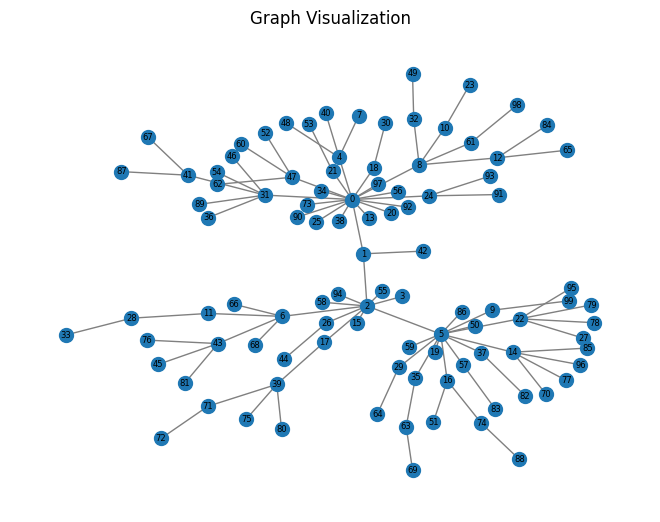

In [68]:
G = nx.barabasi_albert_graph(n=100, m=1, seed=0)
draw_graph(G, node_size=100, layout='kamada_kawai', font_size=6)

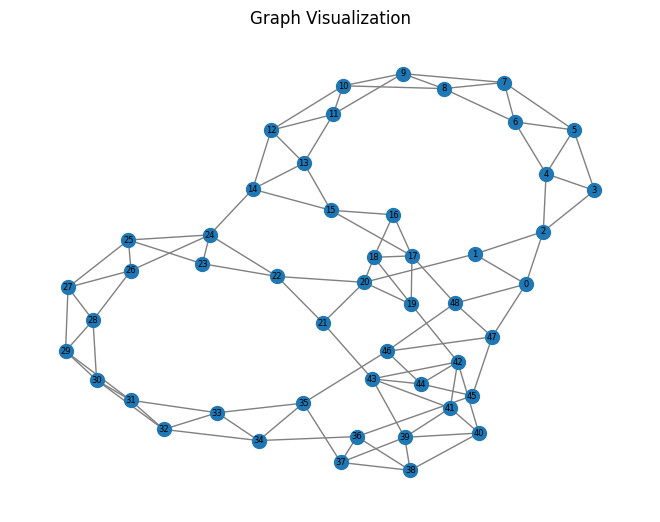

In [56]:
ws_graph = nx.watts_strogatz_graph(n=49, k=4, p=0.1, seed=0)
draw_graph(ws_graph, node_size=100, layout='kamada_kawai', font_size=6)

In [69]:
components = expander_decomposition(G, phi_threshold=0.2)

for i, comp in enumerate(components):
    print(f"Component {i}: {len(comp)} nodes")


Component 0: 50 nodes
Component 1: 25 nodes
Component 2: 25 nodes


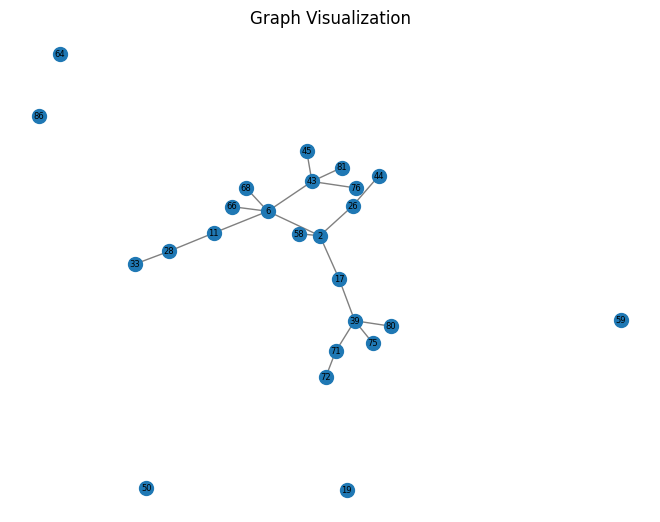

In [78]:
draw_graph(components[1], node_size=100, layout='spring', font_size=6)

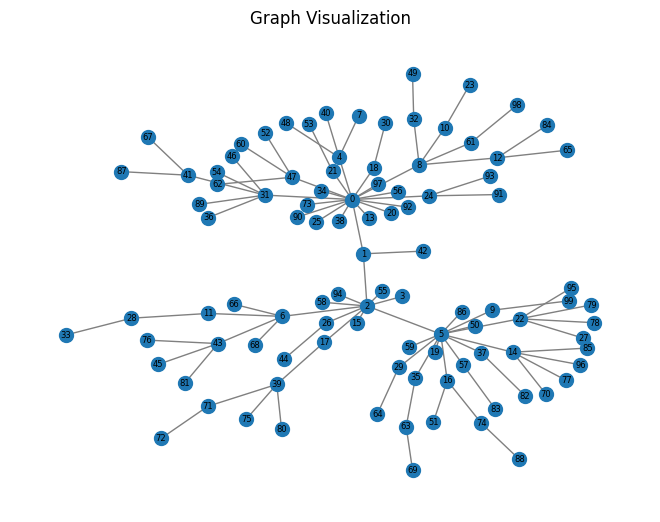

In [ ]:
import networkx as nx
from collections import deque, defaultdict

def low_diameter_decomposition(G, diameter_bound):
    visited = set()
    clusters = []
    node_to_cluster = {}
    cluster_id = 0

    for node in G.nodes():
        if node in visited:
            continue

        # BFS to get a low-diameter cluster
        queue = deque([(node, 0)])
        cluster_nodes = set()
        while queue:
            current, dist = queue.popleft()
            if current in visited or dist > diameter_bound:
                continue
            visited.add(current)
            cluster_nodes.add(current)
            for neighbor in G.neighbors(current):
                if neighbor not in visited:
                    queue.append((neighbor, dist + 1))

        for n in cluster_nodes:
            node_to_cluster[n] = cluster_id
        clusters.append(cluster_nodes)
        cluster_id += 1

    return clusters, node_to_cluster

def build_cluster_tree(G, clusters, node_to_cluster):
    cluster_graph = nx.Graph()
    for i in range(len(clusters)):
        cluster_graph.add_node(i)

    for u, v in G.edges():
        cu, cv = node_to_cluster[u], node_to_cluster[v]
        if cu != cv:
            cluster_graph.add_edge(cu, cv)
    # return cluster_graph

    # Spanning tree over cluster graph
    tree = nx.minimum_spanning_tree(cluster_graph)
    return tree

G = nx.barabasi_albert_graph(n=100, m=1, seed=0)
draw_graph(G)

Number of clusters: 5
Cluster 0: diameter = 6
Cluster 1: diameter = 3
Cluster 2: diameter = 3
Cluster 3: diameter = 3
Cluster 4: diameter = 3
Cluster tree has 5 nodes and 6 edges


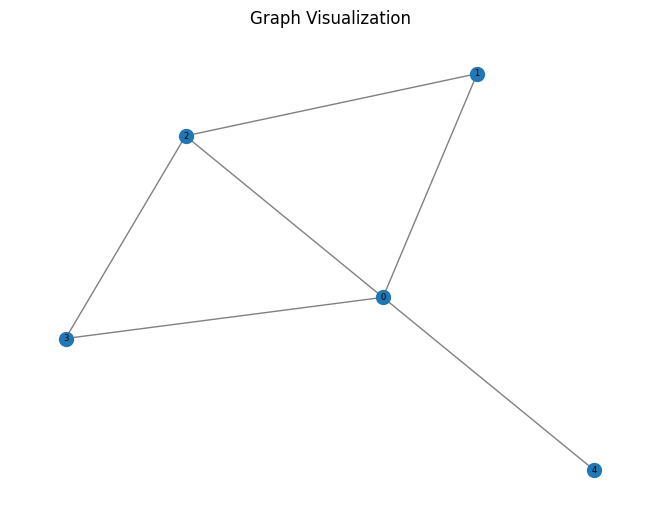

In [63]:
clusters, node_to_cluster = low_diameter_decomposition(ws_graph, diameter_bound=3)

print(f"Number of clusters: {len(clusters)}")
for i, c in enumerate(clusters):
    sub = ws_graph.subgraph(c)
    if nx.is_connected(sub):
        print(f"Cluster {i}: diameter = {nx.diameter(sub)}")
    else:
        print(f"Cluster {i}: not connected!")

cluster_tree = build_cluster_tree(ws_graph, clusters, node_to_cluster)
print(f"Cluster tree has {len(cluster_tree.nodes())} nodes and {len(cluster_tree.edges())} edges")
draw_graph(cluster_tree)

In [67]:
clusters

[{0,
  1,
  2,
  3,
  4,
  5,
  6,
  15,
  16,
  17,
  18,
  19,
  20,
  21,
  22,
  35,
  36,
  44,
  45,
  46,
  47,
  48},
 {7, 8, 9, 10, 11, 12, 13},
 {14, 23, 24, 25, 26, 27, 28},
 {29, 30, 31, 32, 33, 34},
 {37, 38, 39, 40, 41, 42, 43}]

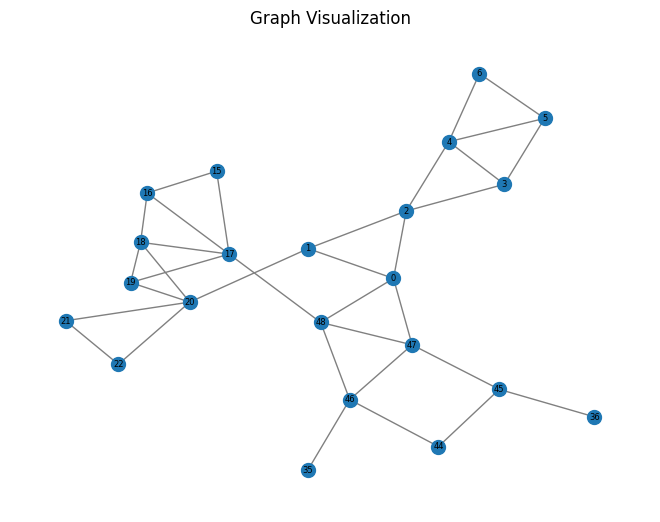

In [65]:
draw_graph(ws_graph.subgraph(clusters[0]))

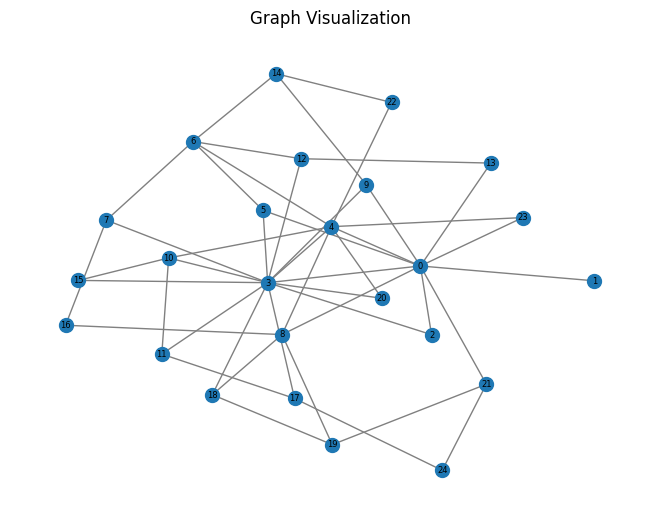

In [49]:
graph = nx.barabasi_albert_graph(n=25, m=2, seed=0)
draw_graph(graph)